# HySfincs: Compound Flooding in the Santoña Estuary

The **Santoña estuary** (Cantabria, Spain) can be flooded by the **sea**, the
**Asón river** and the **rain**, often at the same time. We build a hybrid
model in three steps:

1. Sample the space of possible days (**LHS**) and select **100
   representative scenarios** (**MDA**).
2. Simulate each day with **SFINCS**.
3. Compress the maximum water levels with **PCA**, the training data of a surrogate
   model.

> **Inputs** (`data/`): daily forcing `data_hycoffee_sfincs.nc`, SCS unit
> hydrograph `UH_SCS.xlsx`, topobathymetry `bati_santona.tif`, and the
> model contour `Contorno_malla.gpkg`.
>
> **Outputs:** the SFINCS cases (`cases/`), the static model files
> (`templates/`) and the PCA model and scenarios (`export/`), used by
> `02_Surrogate.ipynb`.

In [1]:
import logging
import os
import os.path as op
import warnings

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import rioxarray  # noqa: F401 (adds the .rio accessor)
import xarray as xr

# Hide warnings and log messages (errors are still shown)
warnings.filterwarnings("ignore")
logging.disable(logging.WARNING)

root_dir = os.getcwd()
data_dir = op.join(root_dir, "data")
templates_dir = op.join(root_dir, "templates")
output_dir = op.join(root_dir, "cases")
export_dir = op.join(root_dir, "export")
pretrained_dir = op.join(root_dir, "pretrained")  # results we provide
os.makedirs(templates_dir, exist_ok=True)
os.makedirs(output_dir, exist_ok=True)
os.makedirs(export_dir, exist_ok=True)

## 1. Scenarios: LHS + MDA

Each scenario (one day) is defined by three variables, whose ranges are taken
from the 10 years of daily data at Santoña:

| Variable | Description |
|:---------|:------------|
| `TWL` | Daily maximum total water level (tide + surge + setup) [m] |
| `Q` | Daily maximum discharge of the Asón at Ampuero [m³/s] |
| `precip_acum` | Daily rainfall [mm] |

Let's first look at the **historical days** (2008–2018):

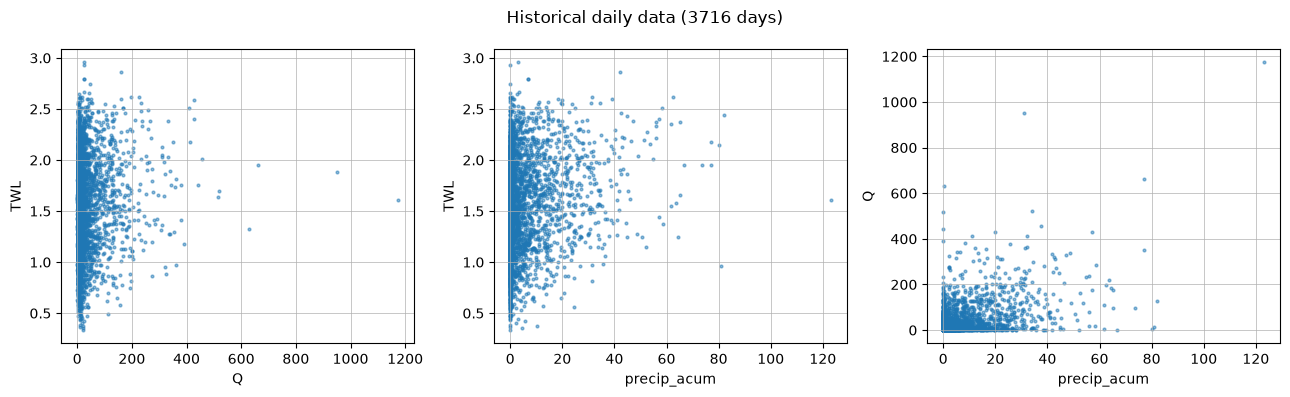

In [2]:
df_hist = xr.open_dataset(op.join(data_dir, "data_hycoffee_sfincs.nc")).to_dataframe()

variables = ["TWL", "Q", "precip_acum"]
pairs = [("Q", "TWL"), ("precip_acum", "TWL"), ("precip_acum", "Q")]

fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, (x, y) in zip(axes, pairs):
    ax.scatter(df_hist[x], df_hist[y], s=4, alpha=0.5)
    ax.set(xlabel=x, ylabel=y)
    ax.grid(lw=0.5)
fig.suptitle(f"Historical daily data ({len(df_hist)} days)")
plt.tight_layout()
plt.show()

We first cover the parameter space with a **Latin Hypercube
Sampling (LHS)** and then select the **100 most different scenarios** with
the **MDA**.

Sampling the variables independently produces some combinations that are not
physical, such as a river flood without rain. River discharge and rainfall
are linked (rain generates the runoff), so we keep only the samples inside
the **convex hull of the observed (`Q`, `precip_acum`) pairs**. The `TWL` is
driven by the tide, the storm surge and the waves, which are independent of
the river, so it is left free: this keeps compound events such as a high
`TWL` together with a river flood.

13457 physically plausible scenarios


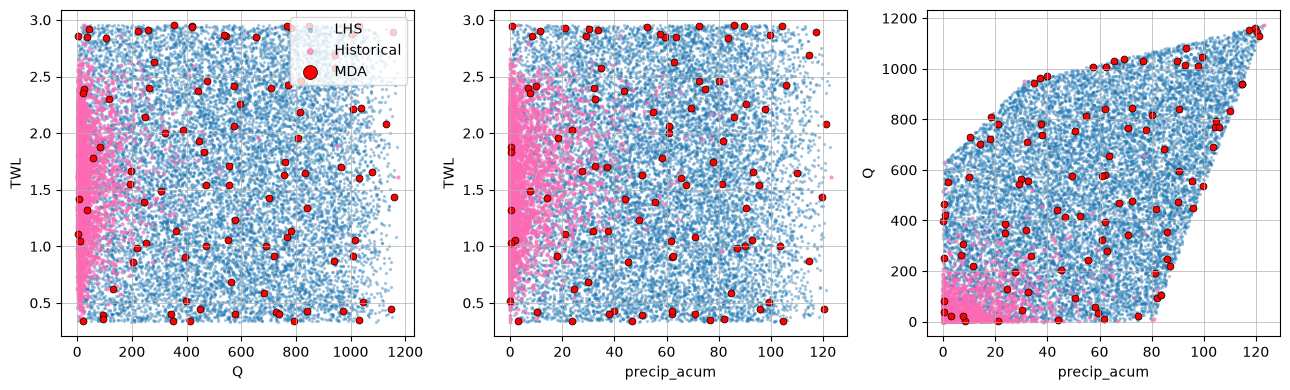

In [3]:
from bluemath_tk.datamining.lhs import LHS
from bluemath_tk.datamining.mda import MDA

from utils.sampling import inside_convex_hull

variables_bounds = {var: (df_hist[var].min(), df_hist[var].max()) for var in variables}

# Fixed seed: you get the same 100 scenarios as in pretrained/
lhs = LHS(num_dimensions=len(variables), seed=1)
df_dataset = lhs.generate(
    dimensions_names=variables,
    lower_bounds=[bounds[0] for bounds in variables_bounds.values()],
    upper_bounds=[bounds[1] for bounds in variables_bounds.values()],
    num_samples=20_000,
)

# Keep the physically plausible (Q, precip_acum) combinations
inside = inside_convex_hull(df_dataset, df_hist, columns=["Q", "precip_acum"])
df_dataset = df_dataset[inside].reset_index(drop=True)
print(f"{len(df_dataset)} physically plausible scenarios")

mda = MDA(num_centers=100)
mda.fit(data=df_dataset, normalize_data=True)

fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, (x, y) in zip(axes, pairs):
    ax.scatter(df_dataset[x], df_dataset[y], s=2, c="tab:blue", alpha=0.3, label="LHS")
    ax.scatter(df_hist[x], df_hist[y], s=4, c="hotpink", alpha=0.6, label="Historical")
    ax.scatter(mda.centroids[x], mda.centroids[y], s=25, c="red", edgecolor="k", lw=0.5, label="MDA")
    ax.set(xlabel=x, ylabel=y)
    ax.grid(lw=0.5)
axes[0].legend(markerscale=2)
plt.tight_layout()
plt.show()

## 2. From daily values to SFINCS forcing

SFINCS needs time series, so each daily value is turned into a one-day
signal. The sea peaks at **hour 12**, while the river peak is shifted by a
**random lag of 2–6 h** (before or after), different in each case: the
flood wave of the Asón and the high tide rarely arrive at the same time.

- **Sea** (`sfincs.bzs`): a **triangle** from $TWL_{min}$ to `TWL` and back.
  Since the tide oscillates around the mean sea level and the residual
  (surge + setup, $NTR$) is nearly constant during the day,
  $TWL_{min} = 2\,\overline{NTR} - TWL$.
- **River** (`sfincs.dis`): the **SCS unit hydrograph** (12 h rising time),
  scaled so that its peak is `Q` and shifted by the lag.
- **Rain** (`sfincs.precip`): constant intensity, `precip_acum / 24` mm/h.

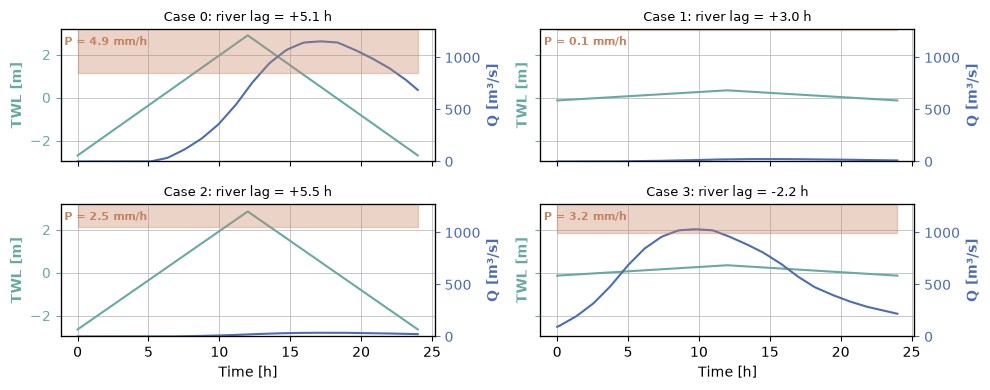

In [4]:
from utils.forcing import (
    build_discharge_forcings,
    build_precipitation_forcings,
    build_twl_forcings,
    random_peak_lags,
    triangular_twl_minimum,
)
from utils.plotting import plot_hysfincs_forcings

sfincs_ref = "2000-01-01 00:00:00"

# Mean non-tidal residual: TWL - tide, with tide = waterlevel - surge
ntr_mean = (df_hist["TWL"] - (df_hist["waterlevel"] - df_hist["surge"])).mean()

waterlevel_forcing = build_twl_forcings(
    twl_max=mda.centroids["TWL"].values,
    twl_min=triangular_twl_minimum(mda.centroids["TWL"].values, ntr_mean),
    reference_time=sfincs_ref,
)

uh = pd.read_excel(op.join(data_dir, "UH_SCS.xlsx"), header=None, names=["t/tp", "q/qp"])
# Random lag between the river and the sea peaks: ±(2-6) h, never 0
river_lag = random_peak_lags(n_cases=len(mda.centroids), min_lag=2, max_lag=6, seed=0)

discharge_forcing = build_discharge_forcings(
    discharge=mda.centroids["Q"].values,
    uh=uh,
    reference_time=sfincs_ref,
    time_to_peak=12,
    peak_hours=12 + river_lag,
)

precipitation_forcing = build_precipitation_forcings(
    precipitation=mda.centroids["precip_acum"].values,
    reference_time=sfincs_ref,
)

fig, axes = plot_hysfincs_forcings(
    waterlevel_forcing[:4],
    discharge_forcing[:4],
    precipitation_forcing[:4],
    reference_time=sfincs_ref,
    titles=[f"Case {i}: river lag = {lag:+.1f} h" for i, lag in enumerate(river_lag[:4])],
)
plt.show()

## 3. SFINCS model

We are interested in the flooding **from the mouth inwards**. The model
contour `Contorno_malla.gpkg` is therefore **closed at the mouth of the
ría**, with a line from the tip of El Puntal northwards to Santoña: the sea
outside that line is left out of the model. The mouth line is the
**water-level boundary** where the TWL is imposed, and the **Asón** enters
at the southern edge.

We use a 100 m grid with **subgrid** tables built from a 20 m DEM.

In [5]:
from rasterio.enums import Resampling
from shapely.geometry import LineString

from utils.domain import close_at_mouth

epsg = 25830  # UTM zone 30N

# Topobathymetry in UTM, 20 m
dem = xr.open_dataarray(op.join(data_dir, "bati_santona.tif")).squeeze(drop=True)
dem_utm = dem.rio.reproject(f"EPSG:{epsg}", resolution=20, resampling=Resampling.bilinear)
dem_utm = dem_utm.where(dem_utm > -1e30)
dem_utm.rio.write_nodata(np.nan, encoded=True, inplace=True)
dem_path = op.join(templates_dir, "dem_santona_utm.tif")
dem_utm.rio.to_raster(dem_path)

# Line across the mouth: from the tip of El Puntal northwards to Santoña
mouth_line = LineString([(463527.0, 4809150.0), (463527.0, 4810000.0)])

# Model contour closed at the mouth
gdf_contour = gpd.read_file(op.join(data_dir, "Contorno_malla.gpkg"))
gdf_domain = close_at_mouth(
    dem=dem_utm,
    gdf_contour=gdf_contour,
    mouth_line=mouth_line,
    inner_point=(462800.0, 4806000.0),  # any point inside the estuary
)

In [6]:
from utils.sfincs_wrapper import SfincsModelWrapper


def points(xs, ys, **kwargs):
    return gpd.GeoDataFrame(geometry=gpd.points_from_xy(xs, ys), crs=epsg, **kwargs)


fixed_parameters = {
    # Grid
    "x0": 457800.0, "y0": 4797800.0, "dx": 100.0, "dy": 100.0,
    "nmax": 175, "mmax": 127, "rotation": 0, "epsg": epsg,
    # Topobathymetry, active cells and subgrid
    "path_to_dem_tif": dem_path,
    "mask_polygon": gdf_domain,
    "mask_zmax": 10.0,
    "mask_fill_area": 0.0,
    "mask_drop_area": 1.0,
    "nr_subgrid_pixels": 8,
    # Water-level boundary: submerged cells along the mouth line
    "waterlevel_include_mask": gpd.GeoDataFrame(geometry=[mouth_line.buffer(100)], crs=epsg),
    "waterlevel_zmax": 0.0,
    # TWL boundary point and Asón inflow (index = column of the discharge forcing)
    "gdf_boundary_points": points([463527.0], [4809480.0]),
    "gdf_river_points": points([464870.0], [4798000.0], index=[1]),
    # Map output every hour
    "dtout": 3600,
}

sfincs_wrapper = SfincsModelWrapper(
    templates_dir=templates_dir,
    templates_name=["sfincs.ind", "sfincs.msk", "sfincs_subgrid.nc"],
    metamodel_parameters={
        "slowly_waterlevel_forcing": waterlevel_forcing,
        "discharge_forcing": discharge_forcing,
        "precipitation_forcing": precipitation_forcing,
    },
    fixed_parameters=fixed_parameters,
    output_dir=output_dir,
    debug=False,
)

# Static model files (grid, mask, subgrid) in templates/
sf_template = sfincs_wrapper.build_template_case()

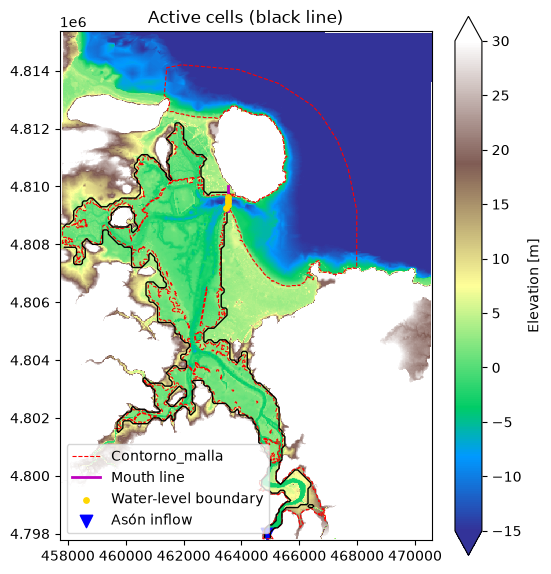

In [7]:
msk = sf_template.grid["msk"]
bnd = msk.where(msk == 2).stack(cell=("y", "x")).dropna("cell")

fig, ax = plt.subplots(figsize=(6, 7))
dem_utm.plot(ax=ax, cmap="terrain", vmin=-15, vmax=30, cbar_kwargs={"label": "Elevation [m]"})
gdf_contour.boundary.plot(ax=ax, color="r", lw=0.8, ls="--", label="Contorno_malla")
ax.contour(msk.x, msk.y, msk > 0, levels=[0.5], colors="k", linewidths=1)
ax.plot(*mouth_line.xy, c="m", lw=2, label="Mouth line")
ax.scatter(bnd.x, bnd.y, s=15, c="gold", zorder=5, label="Water-level boundary")
fixed_parameters["gdf_river_points"].plot(ax=ax, marker="v", color="b", markersize=80, label="Asón inflow")
ax.set(title="Active cells (black line)", xlabel="", ylabel="", aspect="equal")
ax.legend(loc="lower left")
plt.show()

Now we build and run the 100 cases. Each one takes about 2 s, so the whole
set runs in a few minutes.

> If SFINCS is not available on your machine, set `run_sfincs = False`: the
> rest of the notebook then uses the results we provide in `pretrained/`
> (the same 100 scenarios, thanks to the fixed seed of the LHS).

In [8]:
import contextlib
import io

from utils.sfincs_wrapper import default_launcher

run_sfincs = True

# "serial" = the `sfincs` executable of the course container. Elsewhere it falls
# back to an Apptainer image (env. variable SFINCS_SIF) or Docker
launcher = default_launcher()

if run_sfincs:
    with contextlib.redirect_stdout(io.StringIO()):  # hide the "Building case..." messages
        sfincs_wrapper.build_cases()

    # One OpenMP thread per case and one case per core: the fastest for small models
    os.environ.setdefault("OMP_NUM_THREADS", "1")
    sfincs_wrapper.run_cases_with_progress(launcher=launcher, num_workers=os.cpu_count())

SFINCS cases finished: 100/100

In [9]:
from utils.postprocessing import water_level_cases

if run_sfincs:
    cases_run = [op.exists(op.join(output_dir, f"{i:04d}", "sfincs_map.nc")) for i in range(len(mda.centroids))]
    print(f"SFINCS cases run: {sum(cases_run)} of {len(cases_run)}")
    assert all(cases_run), "Some SFINCS cases failed, check the launcher"
    water_levels = water_level_cases(cases_dir=output_dir, n_cases=len(mda.centroids))
else:
    print("Using the SFINCS results in pretrained/")
    water_levels = xr.open_dataset(op.join(pretrained_dir, "sfincs_water_levels.nc"))

SFINCS cases run: 100 of 100


## 4. Flood maps

SFINCS gives the **maximum water level** of each case on its 100 m grid
(cells that never get wet take the level of their bed). Thanks to the
subgrid approach, we obtain the **maximum water depth** on the 20 m DEM as
depth = max(water level − terrain, 0).

To see the effect of each driver, we pick the simulated cases closest to six
contrasting situations: all the drivers low, only one of them high (sea,
river or rain), sea and river high, and all of them high.

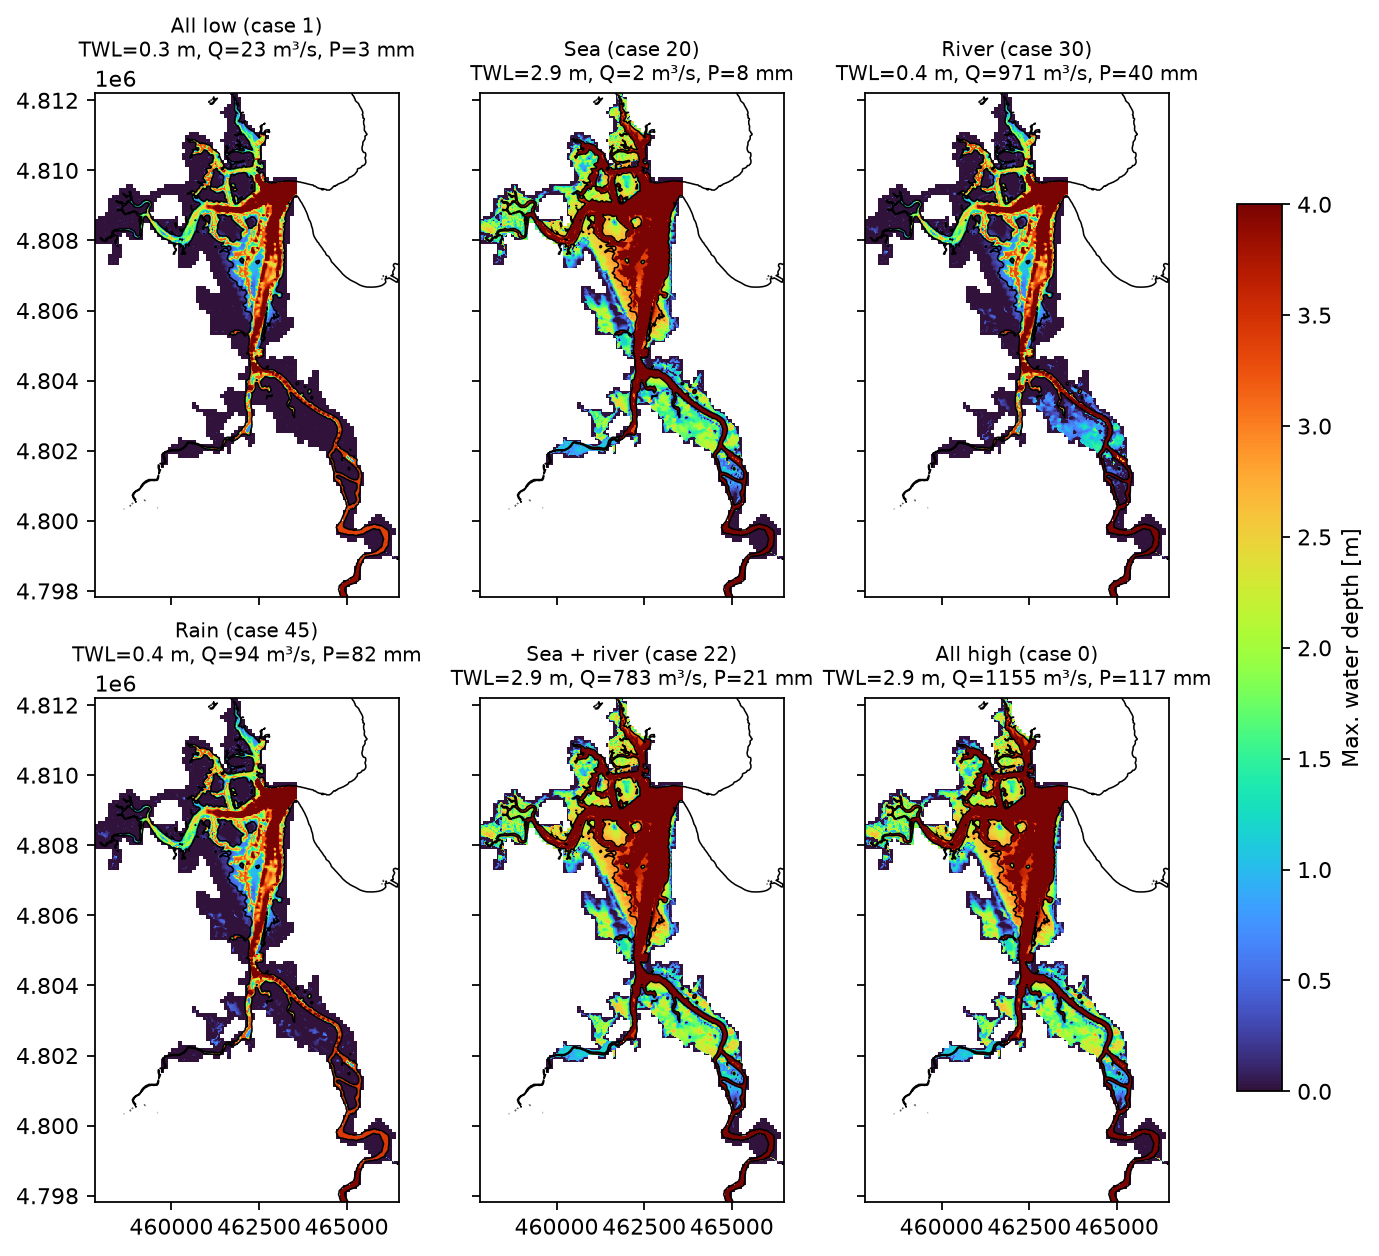

In [10]:
from utils.plotting import plot_output_cases
from utils.postprocessing import water_level_to_depth

dep_hr = xr.open_dataset(dem_path)

# Situations to show: (TWL, Q, precip_acum), 0 = minimum and 1 = maximum of each variable
situations = {
    "All low": [0, 0, 0],
    "Sea": [1, 0, 0],
    "River": [0, 1, 0],
    "Rain": [0, 0, 1],
    "Sea + river": [1, 1, 0],
    "All high": [1, 1, 1],
}

normalized = (mda.centroids[variables] - mda.centroids[variables].min()) / (
    mda.centroids[variables].max() - mda.centroids[variables].min()
)
cases = [int(((normalized - target) ** 2).sum(axis=1).idxmin()) for target in situations.values()]

fig, axes = plot_output_cases(
    list(water_level_to_depth(water_levels["zs"].isel(case_num=cases), dep_hr)),
    dep_hr,
    cmap="turbo",
    vmin=0,
    vmax=4,
    label="Max. water depth [m]",
    figsize=(11, 9),
    titles=[
        f"{name} (case {i})\nTWL={mda.centroids['TWL'].iloc[i]:.1f} m, "
        f"Q={mda.centroids['Q'].iloc[i]:.0f} m³/s, P={mda.centroids['precip_acum'].iloc[i]:.0f} mm"
        for name, i in zip(situations, cases)
    ],
)
plt.show()

## 5. PCA

We describe the 100 maximum **water level** maps with a few spatial patterns
(**EOFs**) and their weights in each case (**PCs**), keeping 99.9% of the
variance. The water level is a smooth surface defined in every active cell,
which the PCA captures with few components; the flood maps are then obtained
from it with the DEM, as above. The data are not standardized, since all the
cells have the same units.

The PCA model, the MDA cases and the LHS dataset are exported to train the
surrogate model.

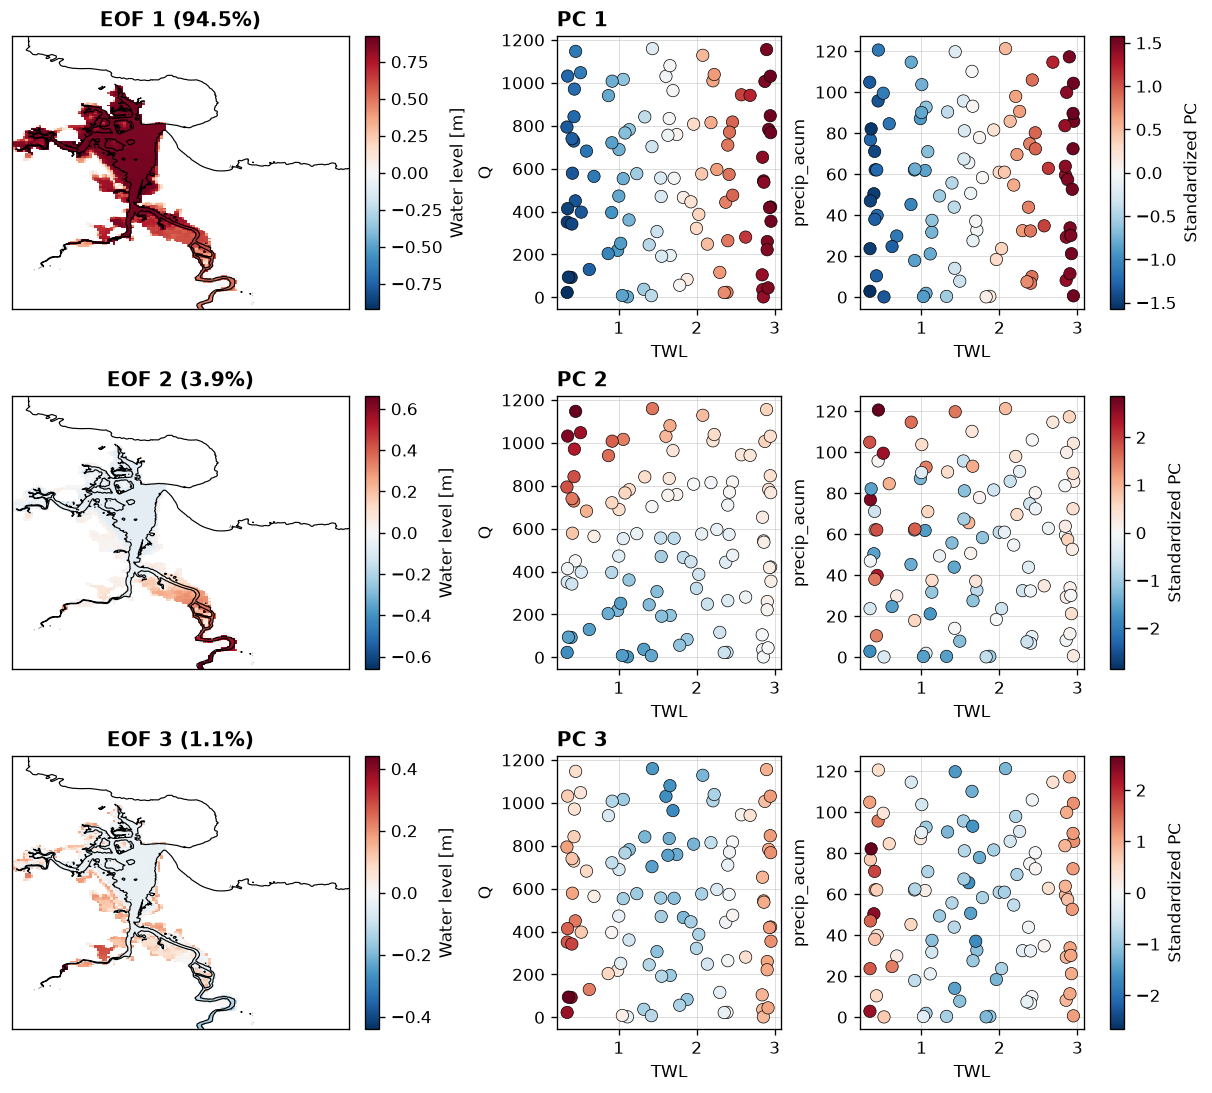

In [11]:
from bluemath_tk.datamining.pca import PCA

from utils.plotting import plot_pca_eofs_pcs

pca = PCA(n_components=0.999)
pca.fit_transform(
    data=water_levels,
    vars_to_stack=["zs"],
    coords_to_stack=["x", "y"],
    pca_dim_for_rows="case_num",
    value_to_replace_nans={"zs": 0.0},
    scale_data=False,
)

pca.save_model(model_path=op.join(export_dir, "pca_model.pkl"))
mda.centroids.to_pickle(op.join(export_dir, "mda_centroids.pkl"))
df_dataset.to_pickle(op.join(export_dir, "lhs_dataset.pkl"))

fig, axs = plot_pca_eofs_pcs(
    pca,
    dep_hr,
    "zs",
    inputs=mda.centroids,
    pairs=[("TWL", "Q"), ("TWL", "precip_acum")],
    n_components=3,
    dpi=120,
    label="Water level [m]",
)
plt.show()

In [12]:
print(f"{pca.pcs_df.shape[1]} PCs explain {100 * pca.explained_variance_ratio.sum():.2f}% of the variance")
for i, cum in enumerate(pca.explained_variance_ratio.cumsum(), start=1):
    print(f"  PC{i}: {100 * cum:.2f}%")

8 PCs explain 99.90% of the variance
  PC1: 94.51%
  PC2: 98.42%
  PC3: 99.53%
  PC4: 99.71%
  PC5: 99.78%
  PC6: 99.83%
  PC7: 99.87%
  PC8: 99.90%


## Summary

We turned daily sea level, river discharge and rainfall into SFINCS forcing,
simulated 100 representative days of the Santoña estuary and compressed the
water levels with PCA. In the next notebook we train an RBF surrogate model
that predicts the PCs from (`TWL`, `Q`, `precip_acum`).